## Exercise 6 - Text Similarity

**Anggota Kelompok :**

*1. Kane Matthew Prastersen - 25031554141*

*2. Nayla Salsabila Az Zahra - 25031554268*

# **TEXT SIMILARITY PART 1**

In [1]:
import warnings
warnings.filterwarnings(action='ignore')

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 80)

## Cosine Similarity

In [2]:
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import CountVectorizer

documents = ["ihsg menguat rupiah stabil",
             "pemerintah atur subsidi dan stimulus ekonomi",
             "rupiah melemah ihsg dan stimulus pemerintah"]

# Mengubah teks menjadi numerik (BoW)
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(documents)

# Menghitung cosine similarity
similarity = cosine_similarity(X)
print(similarity)

[[1.         0.         0.40824829]
 [0.         1.         0.5       ]
 [0.40824829 0.5        1.        ]]


In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Mengubah teks menjadi matriks TF-IDF
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(documents)

# Menghitung cosine similarity
similarity = cosine_similarity(X)
print(similarity)

[[1.         0.         0.33002599]
 [0.         1.         0.40419764]
 [0.33002599 0.40419764 1.        ]]


In [4]:
from scipy.spatial.distance import pdist

vectorizer = CountVectorizer(binary=True)
X = vectorizer.fit_transform(documents).toarray()
print(X)

# pdist menghasilkan jarak, similarity = 1 - jarak
# urutan pasangan: (doc1,doc2), (doc1,doc3), (doc2,doc3)
similarities = 1 - pdist(X, metric='cosine')
print(similarities)

[[0 0 0 1 0 1 0 1 1 0 0]
 [1 1 1 0 0 0 1 0 0 1 1]
 [0 1 0 1 1 0 1 1 0 1 0]]
[0.         0.40824829 0.5       ]


## Jaccard

In [5]:
from sklearn.metrics import jaccard_score

vectorizer = CountVectorizer(binary=True)
X = vectorizer.fit_transform(documents).toarray()

# Menghitung jarak Jaccard
distances = pdist(X, metric='jaccard')
print(distances)

# Menghitung similarity antar dokumen
Sd1d2 = jaccard_score(X[0], X[1])  # similarity doc 1 dan doc 2
Sd1d3 = jaccard_score(X[0], X[2])  # similarity doc 1 dan doc 3
Sd2d3 = jaccard_score(X[1], X[2])  # similarity doc 2 dan doc 3

Sd1d2, Sd1d3, Sd2d3

[1.         0.75       0.66666667]


(0.0, 0.25, 0.3333333333333333)

## Applied to the feature engineering before
Sumber data : CNN Indonesia
Kategori : Ekonomi (https://www.cnnindonesia.com/ekonomi)

Data yang dipakai adalah judul berita yang sudah dibersihkan dan diubah menjadi fitur (One Hot, BoW, TF-IDF) seperti pada exercise feature engineering sebelumnya. Kemudian dihitung kemiripan antar judul berita menggunakan Cosine Similarity dan Jaccard Similarity.

In [6]:
import requests
from bs4 import BeautifulSoup

print("Mulai mengambil data dari CNN Indonesia...")

def scrape_page(url):
    headers = {"User-Agent": "Mozilla/5.0"}
    response = requests.get(url, headers=headers, timeout=20)
    if response.status_code != 200:
        print(f"Gagal: {url} status {response.status_code}")
        return []
    soup = BeautifulSoup(response.text, "html.parser")
    hasil = []
    for a in soup.select("a[href*='/ekonomi/20']"):
        h = a.find(["h2", "h3"])
        title = h.get_text(" ", strip=True) if h else (a.get("dtr-ttl") or "")
        if len(title) > 15:
            hasil.append(title)
    return hasil

# Scraping (halaman 1 = halaman utama ekonomi, halaman 2+ = indeks ekonomi)
titles = []
try:
    titles += scrape_page("https://www.cnnindonesia.com/ekonomi")
    for page in range(1, 11):
        titles += scrape_page(f"https://www.cnnindonesia.com/ekonomi/indeks/5?page={page}")
except Exception as e:
    print("Scraping tidak berhasil:", e)

raw_df = pd.DataFrame({"raw_title": titles}).drop_duplicates().reset_index(drop=True)

print(f"Total judul setelah scraping: {len(raw_df)}")
raw_df.head()

Mulai mengambil data dari CNN Indonesia...


Total judul setelah scraping: 101


,raw_title
0,"Buruh Desak Pemerintah Batasi Outsourcing, Hapus Pesangon 0,5 Kali"
1,"Buruh Siapkan Aksi di 38 Provinsi Tuntut Upah Naik 9,5 Persen di 2027"
2,Bagaimana Aturan Pesangon Korban PHK di UU Ketenagakerjaan Baru?
3,14 Daftar Maskapai Batalkan Penerbangan ke Riyadh Imbas Serangan Rudal
4,VIDEO: Berkah Karbon dari Belantara Jambi


In [7]:
# Tahap preprocessing ringan
def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_scraped = raw_df.copy()
df_scraped["prepro"] = df_scraped["raw_title"].apply(preprocess_text)

df_scraped = df_scraped[df_scraped["prepro"].str.len() > 0]
df_scraped = df_scraped.drop_duplicates(subset=["prepro"]).reset_index(drop=True)

df_scraped.to_csv("cnn_ekonomi_preprocessed.csv", index=False)

print(f"Dataset preprocessing tersimpan: {len(df_scraped)} baris")
df_scraped.head()

Dataset preprocessing tersimpan: 101 baris


,raw_title,prepro
0,"Buruh Desak Pemerintah Batasi Outsourcing, Hapus Pesangon 0,5 Kali",buruh desak pemerintah batasi outsourcing hapus pesangon 0 5 kali
1,"Buruh Siapkan Aksi di 38 Provinsi Tuntut Upah Naik 9,5 Persen di 2027",buruh siapkan aksi di 38 provinsi tuntut upah naik 9 5 persen di 2027
2,Bagaimana Aturan Pesangon Korban PHK di UU Ketenagakerjaan Baru?,bagaimana aturan pesangon korban phk di uu ketenagakerjaan baru
3,14 Daftar Maskapai Batalkan Penerbangan ke Riyadh Imbas Serangan Rudal,14 daftar maskapai batalkan penerbangan ke riyadh imbas serangan rudal
4,VIDEO: Berkah Karbon dari Belantara Jambi,video berkah karbon dari belantara jambi


In [8]:
df = pd.read_csv("cnn_ekonomi_preprocessed.csv")
df = df.dropna(subset=["prepro"]).reset_index(drop=True)
df_pre = df["prepro"]
texts = df["raw_title"].tolist()

print("Jumlah dokumen:", len(df_pre))
df_pre.head()

Jumlah dokumen: 101


0         buruh desak pemerintah batasi outsourcing hapus pesangon 0 5 kali
1     buruh siapkan aksi di 38 provinsi tuntut upah naik 9 5 persen di 2027
2           bagaimana aturan pesangon korban phk di uu ketenagakerjaan baru
3    14 daftar maskapai batalkan penerbangan ke riyadh imbas serangan rudal
4                                  video berkah karbon dari belantara jambi
Name: prepro, dtype: str

In [9]:
# Feature engineering (sama seperti exercise sebelumnya)
onehot_vectorizer = CountVectorizer(binary=True, min_df=2, max_features=2000)
X_onehot = onehot_vectorizer.fit_transform(df_pre).toarray()

bow_vectorizer = CountVectorizer(min_df=2, max_features=2000)
X_bow = bow_vectorizer.fit_transform(df_pre)

tfidf_vectorizer = TfidfVectorizer(min_df=2,
                                   max_features=2000,
                                   sublinear_tf=True)
X_tfidf = tfidf_vectorizer.fit_transform(df_pre)

print("Ukuran matriks One Hot:", X_onehot.shape)
print("Ukuran matriks BoW    :", X_bow.shape)
print("Ukuran matriks TF-IDF :", X_tfidf.shape)

Ukuran matriks One Hot: (101, 144)
Ukuran matriks BoW    : (101, 144)
Ukuran matriks TF-IDF : (101, 144)


In [10]:
# Fungsi untuk menampilkan pasangan judul yang paling mirip
def top_similar_pairs(sim_matrix, texts, top_n=10):
    n = sim_matrix.shape[0]
    rows, cols = np.triu_indices(n, k=1)   # pasangan unik, tanpa diagonal
    scores = sim_matrix[rows, cols]
    order = np.argsort(scores)[::-1][:top_n]
    return pd.DataFrame({"judul_1": [texts[i] for i in rows[order]],
                         "judul_2": [texts[j] for j in cols[order]],
                         "similarity": scores[order].round(4)})

## Cosine Similarity pada BoW

In [11]:
sim_bow = cosine_similarity(X_bow)

print("Ukuran similarity matrix BoW:", sim_bow.shape)
top_similar_pairs(sim_bow, texts)

Ukuran similarity matrix BoW: (101, 101)


,judul_1,judul_2,similarity
0,Ayo Daftar Tokoh Muda Inspiratif Penghargaan Energi Subroto di Sini,"Informasi Lengkap Penghargaan Energi Subroto, Ayo Daftar di Sini",1.0000
1,"Harga Emas Antam Merosot Rp20 Ribu Jadi Rp2,574 Juta Hari Ini","Harga Emas Antam Naik Tipis Jadi Rp2,594 Juta Hari Ini",0.8889
2,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi,0.8819
3,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,0.8250
4,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Tak Bertenaga ke Rp17.913 per Dolar AS Sore Ini,0.8250
5,BGN Tutup Permanen 2 Dapur MBG di Jateng,"BGN Uji Coba MBG Prasmanan di 62 Dapur, Target 5.000 SPPG Akhir 2026",0.8165
6,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi,0.8018
7,Koster soal BBM di Bali: Pasokan Tersedia di Depo,Pertamina Tambah Pasokan BBM Pertalite-Pertamax 26.200 KL di Bali,0.7906
8,IHSG Masih Tertahan di Bawah 6.000 Meski 336 Saham Hijau Sore Ini,"IHSG Meradang di Bawah Level 6.000 Sore Ini, 602 Saham Merah",0.7826
9,"Satgas P2BBL Diresmikan, Bergerak Lawan Penyelundupan Benih Lobster","Potensi Benih Lobster 465,8 Juta Ekor, Pemerintah Bentuk Satgas Khusus",0.7746


## Cosine Similarity pada TF-IDF

In [12]:
sim_tfidf = cosine_similarity(X_tfidf)

print("Ukuran similarity matrix TF-IDF:", sim_tfidf.shape)
top_similar_pairs(sim_tfidf, texts)

Ukuran similarity matrix TF-IDF: (101, 101)


,judul_1,judul_2,similarity
0,Ayo Daftar Tokoh Muda Inspiratif Penghargaan Energi Subroto di Sini,"Informasi Lengkap Penghargaan Energi Subroto, Ayo Daftar di Sini",1.0000
1,"Harga Emas Antam Merosot Rp20 Ribu Jadi Rp2,574 Juta Hari Ini","Harga Emas Antam Naik Tipis Jadi Rp2,594 Juta Hari Ini",0.8817
2,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi,0.8521
3,"Satgas P2BBL Diresmikan, Bergerak Lawan Penyelundupan Benih Lobster","Potensi Benih Lobster 465,8 Juta Ekor, Pemerintah Bentuk Satgas Khusus",0.8211
4,BGN Tutup Permanen 2 Dapur MBG di Jateng,"BGN Uji Coba MBG Prasmanan di 62 Dapur, Target 5.000 SPPG Akhir 2026",0.8070
5,BGN Tutup Permanen 2 Dapur MBG di Jateng,BGN Bongkar Modus Penipuan Janjikan Percepatan Aktivasi Dapur MBG,0.8018
6,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Tak Bertenaga ke Rp17.913 per Dolar AS Sore Ini,0.8007
7,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,0.7997
8,Koster soal BBM di Bali: Pasokan Tersedia di Depo,Pertamina Tambah Pasokan BBM Pertalite-Pertamax 26.200 KL di Bali,0.7844
9,Pertamina Patra Niaga Kebut Pemulihan Pasokan BBM Bali 24 Jam,Pertamina Patra Niaga Antisipasi Lonjakan Konsumsi BBM di Bondowoso,0.7780


## Jaccard Similarity pada One Hot

In [13]:
from scipy.spatial.distance import squareform

# Jaccard dihitung dari fitur biner (One Hot), similarity = 1 - jarak
sim_jaccard = 1 - squareform(pdist(X_onehot.astype(bool), metric="jaccard"))
sim_jaccard = np.nan_to_num(sim_jaccard)   # judul tanpa fitur menghasilkan NaN -> 0

print("Ukuran similarity matrix Jaccard:", sim_jaccard.shape)
top_similar_pairs(sim_jaccard, texts)

Ukuran similarity matrix Jaccard: (101, 101)


,judul_1,judul_2,similarity
0,Ayo Daftar Tokoh Muda Inspiratif Penghargaan Energi Subroto di Sini,"Informasi Lengkap Penghargaan Energi Subroto, Ayo Daftar di Sini",1.0000
1,"Harga Emas Antam Merosot Rp20 Ribu Jadi Rp2,574 Juta Hari Ini","Harga Emas Antam Naik Tipis Jadi Rp2,594 Juta Hari Ini",0.8000
2,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi,0.7778
3,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Tak Bertenaga ke Rp17.913 per Dolar AS Sore Ini,0.7000
4,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,0.7000
5,Koster soal BBM di Bali: Pasokan Tersedia di Depo,Pertamina Tambah Pasokan BBM Pertalite-Pertamax 26.200 KL di Bali,0.6667
6,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi,0.6667
7,BGN Tutup Permanen 2 Dapur MBG di Jateng,"BGN Uji Coba MBG Prasmanan di 62 Dapur, Target 5.000 SPPG Akhir 2026",0.6667
8,IHSG Masih Tertahan di Bawah 6.000 Meski 336 Saham Hijau Sore Ini,"IHSG Meradang di Bawah Level 6.000 Sore Ini, 602 Saham Merah",0.6364
9,BRI Jadi Merek Paling Bernilai di Indonesia Versi Brand Finance 2026,"Jadi Panelis di Forum ICAO, AirNav Indonesia Paparkan Penerapan FRTO",0.6000


## Pencarian Judul Berita dengan Query

In [14]:
from scipy.spatial.distance import cdist

TopK = 5

def show_results(similarities, topk=TopK):
    top_indices = similarities.argsort()[::-1][:topk]
    return pd.DataFrame({"Title": [texts[i] for i in top_indices],
                         "Similarities": similarities[top_indices].round(4)})

def search_tfidf(query, vectorizer=tfidf_vectorizer, X_doc=X_tfidf):
    query_tfidf = vectorizer.transform([preprocess_text(query)])
    return cosine_similarity(X_doc, query_tfidf)[:, 0]

def search_jaccard(query, vectorizer=onehot_vectorizer, X_doc=X_onehot):
    query_bin = vectorizer.transform([preprocess_text(query)]).toarray().astype(bool)
    similarities = 1 - cdist(X_doc.astype(bool), query_bin, metric="jaccard")[:, 0]
    return np.nan_to_num(similarities)

In [15]:
query = "harga emas naik"
print("Query:", query)

print("\nCosine TF-IDF")
display(show_results(search_tfidf(query)))

print("Jaccard One Hot")
display(show_results(search_jaccard(query)))

Query: harga emas naik

Cosine TF-IDF


,Title,Similarities
0,"Harga Emas Antam Naik Tipis Jadi Rp2,594 Juta Hari Ini",0.5885
1,"Harga Cabai Merah Naik di 314 Daerah, Tertinggi Rp193 Ribu per Kg",0.4515
2,"Harga Emas Antam Merosot Rp20 Ribu Jadi Rp2,574 Juta Hari Ini",0.3803
3,"Selat Hormuz Sudah Terbuka, Kenapa Harga BBM Masih Mahal?",0.2550
4,"Buruh Siapkan Aksi di 38 Provinsi Tuntut Upah Naik 9,5 Persen di 2027",0.2275


Jaccard One Hot


,Title,Similarities
0,"Harga Emas Antam Naik Tipis Jadi Rp2,594 Juta Hari Ini",0.3333
1,"Harga Cabai Merah Naik di 314 Daerah, Tertinggi Rp193 Ribu per Kg",0.2857
2,"Selat Hormuz Sudah Terbuka, Kenapa Harga BBM Masih Mahal?",0.2000
3,"Harga Emas Antam Merosot Rp20 Ribu Jadi Rp2,574 Juta Hari Ini",0.2000
4,Prabowo Perintahkan Amran Berantas Mafia yang Mainkan Harga Pangan,0.1667


In [16]:
query = "ihsg dan rupiah melemah"
print("Query:", query)

print("\nCosine TF-IDF")
display(show_results(search_tfidf(query)))

print("Jaccard One Hot")
display(show_results(search_jaccard(query)))

Query: ihsg dan rupiah melemah

Cosine TF-IDF


,Title,Similarities
0,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,0.3811
1,Wamenko Dradjad Bantah Daya Beli Melemah,0.3472
2,IHSG Diperkirakan Ceria Awali Pekan Ini,0.2770
3,PT Tiran Nusantara Grup dan Conch Sepakati Investasi Rp10 Triliun,0.2488
4,IHSG Diproyeksi Makin Turun Hari Ini,0.2381


Jaccard One Hot


,Title,Similarities
0,PT Tiran Nusantara Grup dan Conch Sepakati Investasi Rp10 Triliun,0.2000
1,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,0.1818
2,IHSG Diperkirakan Ceria Awali Pekan Ini,0.1667
3,Wamenko Dradjad Bantah Daya Beli Melemah,0.1667
4,Pemerintah Kawal Hilirisasi Nikel agar Ekonomi Tumbuh dan Bermanfaat,0.1667


In [17]:
# Dicoba lagi dengan menghapus stopword bahasa Indonesia
import nltk
nltk.download("stopwords")
from nltk.corpus import stopwords

stop_id = stopwords.words("indonesian")

tfidf_sw = TfidfVectorizer(min_df=2, max_features=2000, sublinear_tf=True, stop_words=stop_id)
X_tfidf_sw = tfidf_sw.fit_transform(df_pre)

onehot_sw = CountVectorizer(binary=True, min_df=2, max_features=2000, stop_words=stop_id)
X_onehot_sw = onehot_sw.fit_transform(df_pre).toarray()

query = "ihsg dan rupiah melemah"
print("Query:", query)

print("\nCosine TF-IDF (tanpa stopword)")
display(show_results(search_tfidf(query, tfidf_sw, X_tfidf_sw)))

print("Jaccard One Hot (tanpa stopword)")
display(show_results(search_jaccard(query, onehot_sw, X_onehot_sw)))

Query: ihsg dan rupiah melemah

Cosine TF-IDF (tanpa stopword)


,Title,Similarities
0,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,0.4554
1,Wamenko Dradjad Bantah Daya Beli Melemah,0.3808
2,IHSG Diproyeksi Makin Turun Hari Ini,0.3458
3,IHSG Diperkirakan Ceria Awali Pekan Ini,0.3458
4,Rupiah Tak Bertenaga ke Rp17.913 per Dolar AS Sore Ini,0.2530


Jaccard One Hot (tanpa stopword)


,Title,Similarities
0,IHSG Diperkirakan Ceria Awali Pekan Ini,0.2500
1,IHSG Diproyeksi Makin Turun Hari Ini,0.2500
2,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,0.2500
3,Wamenko Dradjad Bantah Daya Beli Melemah,0.2000
4,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi,0.1429


## Analisis Text Similarity 1

Hasil analisis setelah notebook dijalankan.

Cosine Similarity pada BoW dan TF-IDF serta Jaccard pada One Hot menghasilkan pasangan judul paling mirip yang hampir sama, yaitu judul tentang kurs rupiah per dolar AS, harga emas Antam, IHSG di bawah level 6.000, pasokan BBM di Bali, dan dapur MBG. Pasangan dengan nilai 1.0 berarti kedua judul memiliki kata fitur yang sama persis, hanya urutannya berbeda. TF-IDF memberi bobot lebih kecil pada kata yang terlalu umum sehingga kemiripan lebih ditentukan oleh kata yang khas seperti "emas", "antam", dan "rupiah", sedangkan Jaccard paling ketat karena hanya membandingkan irisan dan gabungan kata tanpa bobot. Karena judul berita sangat pendek, sebagian besar pasangan judul (sekitar 80%) tidak memiliki kata yang sama sehingga nilai similarity-nya 0.

Pada pencarian dengan query "harga emas naik", kedua metode menempatkan judul "Harga Emas Antam Naik Tipis" di posisi pertama. Namun pada query "ihsg dan rupiah melemah", kata umum "dan" ikut dihitung sehingga Jaccard mengambil judul yang tidak relevan di posisi pertama. Setelah stopword bahasa Indonesia dihapus, hasil TF-IDF dan Jaccard langsung berisi judul tentang rupiah melemah dan IHSG. Artinya preprocessing (stopword removal) sangat berpengaruh pada hasil text similarity. Kelemahan metode berbasis kata adalah tidak memahami makna, misalnya "rupiah menguat" dan "rupiah bangkit" dianggap mirip hanya karena kata "rupiah", "dolar", dan "as".

# **TEXT SIMILARITY PART 2 (WORD EMBEDDINGS)**

In [18]:
import nltk
nltk.download("punkt")
nltk.download("punkt_tab")

from nltk import word_tokenize
from tqdm import tqdm

sentences = [word_tokenize(str(news).lower())
             for news in tqdm(df_pre, desc="Tokenisasi")]

sentences[:2]

Tokenisasi:   0%|          | 0/101 [00:00<?, ?it/s]

Tokenisasi:   1%|          | 1/101 [00:01<01:55,  1.16s/it]

Tokenisasi: 100%|██████████| 101/101 [00:01<00:00, 86.80it/s]

[['buruh',
  'desak',
  'pemerintah',
  'batasi',
  'outsourcing',
  'hapus',
  'pesangon',
  '0',
  '5',
  'kali'],
 ['buruh',
  'siapkan',
  'aksi',
  'di',
  '38',
  'provinsi',
  'tuntut',
  'upah',
  'naik',
  '9',
  '5',
  'persen',
  'di',
  '2027']]

## Build Word2Vec Model

In [19]:
!pip install gensim

In [20]:
import gensim.models

model = gensim.models.Word2Vec(sentences,
                               min_count=2,
                               vector_size=100,
                               window=5,
                               sg=0,
                               epochs=20,
                               workers=1,
                               seed=42)

parameter Word2Vec

*   min_count=2: hanya kata yang muncul minimal 2 kali.
*   vector_size=100: setiap kata direpresentasikan dalam 100 dimensi.
*   window=5: konteks kata diambil dari jendela 5 kata.
*   sg=0: menggunakan CBOW
*   epochs=20: model dilatih beberapa putaran agar representasi lebih stabil.
*   workers=1 dan seed=42: hasil sama setiap notebook dijalankan ulang.

In [21]:
# Vektor dokumen = rata-rata vektor kata pada judul
def get_document_vector(tokens, model):
    valid_vectors = [model.wv[word] for word in tokens
                     if word in model.wv.key_to_index]

    if not valid_vectors:
        return np.zeros(model.vector_size)

    return np.mean(valid_vectors, axis=0)

X_w2v = np.array([get_document_vector(doc, model)
                  for doc in sentences])

print("Ukuran fitur dokumen Word2Vec:", X_w2v.shape)

Ukuran fitur dokumen Word2Vec: (101, 100)


## Cosine Similarity pada Word2Vec

In [22]:
sim_w2v = cosine_similarity(X_w2v)

print("Ukuran similarity matrix Word2Vec:", sim_w2v.shape)
top_similar_pairs(sim_w2v, texts)

Ukuran similarity matrix Word2Vec: (101, 101)


,judul_1,judul_2,similarity
0,Ayo Daftar Tokoh Muda Inspiratif Penghargaan Energi Subroto di Sini,"Informasi Lengkap Penghargaan Energi Subroto, Ayo Daftar di Sini",1.0000
1,"Harga Emas Antam Merosot Rp20 Ribu Jadi Rp2,574 Juta Hari Ini","Harga Emas Antam Naik Tipis Jadi Rp2,594 Juta Hari Ini",0.9381
2,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi,0.9247
3,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,0.9118
4,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi,0.8924
5,IHSG Masih Tertahan di Bawah 6.000 Meski 336 Saham Hijau Sore Ini,"IHSG Meradang di Bawah Level 6.000 Sore Ini, 602 Saham Merah",0.8907
6,Rupiah Tak Bertenaga ke Rp17.913 per Dolar AS Sore Ini,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi,0.8837
7,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Tak Bertenaga ke Rp17.913 per Dolar AS Sore Ini,0.8742
8,Koster soal BBM di Bali: Pasokan Tersedia di Depo,Pertamina Tambah Pasokan BBM Pertalite-Pertamax 26.200 KL di Bali,0.8252
9,Kemenkeu Siapkan Pencairan Tunjangan Guru yang Nunggak 3 Bulan,"Tunjangan Profesi Guru Nunggak 3 Bulan, DPR Minta Menkeu Cairkan Cepat",0.8222


In [23]:
def search_embedding(query, model, X_doc):
    query_vector = get_document_vector(word_tokenize(preprocess_text(query)), model)
    return cosine_similarity(X_doc, query_vector.reshape(1, -1))[:, 0]

for query in ["harga emas naik", "ihsg dan rupiah melemah"]:
    print("Query:", query)
    display(show_results(search_embedding(query, model, X_w2v)))

Query: harga emas naik


,Title,Similarities
0,"Harga Emas Antam Naik Tipis Jadi Rp2,594 Juta Hari Ini",0.7007
1,"Harga Emas Antam Merosot Rp20 Ribu Jadi Rp2,574 Juta Hari Ini",0.5845
2,"Harga Cabai Merah Naik di 314 Daerah, Tertinggi Rp193 Ribu per Kg",0.5028
3,"4,8 Juta Peternak Terancam Bangkrut Imbas Harga Ayam dan Telur Anjlok",0.4315
4,"Selat Hormuz Sudah Terbuka, Kenapa Harga BBM Masih Mahal?",0.3363


Query: ihsg dan rupiah melemah


,Title,Similarities
0,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,0.5523
1,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,0.4470
2,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi,0.4390
3,Rupiah Tak Bertenaga ke Rp17.913 per Dolar AS Sore Ini,0.4342
4,Robert E Hall dan Michael Woodford Jadi Peraih Nobel Ekonomi 2026,0.4165


## Build FastText Model

In [24]:
model_fasttext = gensim.models.FastText(sentences,
                                        min_count=2,
                                        vector_size=100,
                                        window=5,
                                        min_n=3,
                                        max_n=6,
                                        sg=1,
                                        epochs=20,
                                        workers=1,
                                        seed=42)

parameter FastText

*   min_count=2: buang kata yang terlalu jarang muncul.
*   vector_size=100: tiap kata punya 100 angka fitur.
*   window=5: lihat konteks 5 kata di sekitar.
*   min_n=3, max_n=6: pakai potongan huruf 3-6 karakter.
*   sg=1: metode Skip-Gram, tebak kata sekitar.
*   epochs=20: latih model 20 kali putaran.

In [25]:
X_fasttext = np.array([get_document_vector(doc, model_fasttext)
                       for doc in sentences])

print("Ukuran fitur dokumen FastText:", X_fasttext.shape)

Ukuran fitur dokumen FastText: (101, 100)


## Cosine Similarity pada FastText

In [26]:
sim_fasttext = cosine_similarity(X_fasttext)

print("Ukuran similarity matrix FastText:", sim_fasttext.shape)
top_similar_pairs(sim_fasttext, texts)

Ukuran similarity matrix FastText: (101, 101)


,judul_1,judul_2,similarity
0,Ayo Daftar Tokoh Muda Inspiratif Penghargaan Energi Subroto di Sini,"Informasi Lengkap Penghargaan Energi Subroto, Ayo Daftar di Sini",1.0000
1,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi,0.9969
2,"Harga Emas Antam Merosot Rp20 Ribu Jadi Rp2,574 Juta Hari Ini","Harga Emas Antam Naik Tipis Jadi Rp2,594 Juta Hari Ini",0.9965
3,IHSG Masih Tertahan di Bawah 6.000 Meski 336 Saham Hijau Sore Ini,"IHSG Meradang di Bawah Level 6.000 Sore Ini, 602 Saham Merah",0.9953
4,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,0.9946
5,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi,0.9925
6,Rupiah Menguat ke Rp17.900 per Dolar AS Selasa Sore,Rupiah Tak Bertenaga ke Rp17.913 per Dolar AS Sore Ini,0.9924
7,Harga Minyak Dunia Turun Usai Trump Izinkan Rusia Pasok Diesel Global,Harga Minyak Dunia Anjlok Usai Trump Klaim Rusia-Ukraina Sepakat Damai,0.9907
8,Rupiah Dibuka Melemah ke Rp17.948 per Dolar AS Selasa Pagi,Rupiah Tak Bertenaga ke Rp17.913 per Dolar AS Sore Ini,0.9898
9,Rupiah Tak Bertenaga ke Rp17.913 per Dolar AS Sore Ini,Rupiah Bangkit ke Rp17.885 per Dolar AS Senin Pagi,0.9894


In [27]:
for query in ["harga emas naik", "ihsg dan rupiah melemah"]:
    print("Query:", query)
    display(show_results(search_embedding(query, model_fasttext, X_fasttext)))

Query: harga emas naik


,Title,Similarities
0,"Harga Emas Antam Naik Tipis Jadi Rp2,594 Juta Hari Ini",0.9699
1,"Harga Emas Antam Merosot Rp20 Ribu Jadi Rp2,574 Juta Hari Ini",0.9623
2,"Harga Cabai Merah Naik di 314 Daerah, Tertinggi Rp193 Ribu per Kg",0.9577
3,"4,8 Juta Peternak Terancam Bangkrut Imbas Harga Ayam dan Telur Anjlok",0.9464
4,"Ada Gangguan Listrik di Batam, Bahlil Bakal Rapat dengan PLN",0.9452


Query: ihsg dan rupiah melemah


,Title,Similarities
0,"Jelang COP31 Turki, Indonesia Incar Investasi Hijau dan Pasar Karbon",0.9650
1,BRI Perkuat Ekonomi Lokal dan Sport Tourism di MotoGP Mandalika 2026,0.9649
2,"Bahlil Dorong UMKM, Koperasi dan Pengusaha Lokal Masuk Bisnis Tambang",0.9646
3,Danantara Bakal Tetap Masuk ke Pasar Saham Meski IHSG Anjlok,0.9615
4,PT Tiran Nusantara Grup dan Conch Sepakati Investasi Rp10 Triliun,0.9613


In [28]:
# Uji kata yang tidak ada di vocabulary
query = "penguatan perekonomian"
tokens = word_tokenize(preprocess_text(query))

print("Ada di vocabulary TF-IDF  :", {t: t in tfidf_vectorizer.vocabulary_ for t in tokens})
print("Ada di vocabulary Word2Vec:", {t: t in model.wv.key_to_index for t in tokens})

# FastText tetap bisa membuat vektor kata baru dari potongan huruf (subword)
query_vector = np.mean([model_fasttext.wv[t] for t in tokens], axis=0)
similarities = cosine_similarity(X_fasttext, query_vector.reshape(1, -1))[:, 0]

print("\nQuery:", query)
show_results(similarities)

Ada di vocabulary TF-IDF  : {'penguatan': False, 'perekonomian': False}
Ada di vocabulary Word2Vec: {'penguatan': False, 'perekonomian': False}

Query: penguatan perekonomian


,Title,Similarities
0,Pemerintah Kawal Hilirisasi Nikel agar Ekonomi Tumbuh dan Bermanfaat,0.9185
1,Amran Blak-blakan 82 Persen Kebutuhan Susu RI Masih Dipenuhi Impor,0.9169
2,BRI Perkuat Ekonomi Lokal dan Sport Tourism di MotoGP Mandalika 2026,0.9153
3,Telkomsel Hadirkan Jaringan Terdepan dan Terluas di MotoGP Mandalika,0.9117
4,Penerbangan Transit Dubai dari RI ke Riyadh dan Jeddah Dibatalkan,0.9104


## Perbandingan Semua Metode

In [29]:
sim_matrices = {"Cosine BoW": sim_bow,
                "Cosine TF-IDF": sim_tfidf,
                "Jaccard One Hot": sim_jaccard,
                "Cosine Word2Vec": sim_w2v,
                "Cosine FastText": sim_fasttext}

rows, cols = np.triu_indices(len(df_pre), k=1)

stats = []
for name, mat in sim_matrices.items():
    values = mat[rows, cols]
    stats.append({"metode": name,
                  "rata_rata": values.mean(),
                  "median": np.median(values),
                  "persen_nilai_0": (values == 0).mean() * 100,
                  "persen_nilai_>0.5": (values > 0.5).mean() * 100})

pd.DataFrame(stats).set_index("metode").round(4)

,rata_rata,median,persen_nilai_0,persen_nilai_>0.5
metode,,,,
Cosine BoW,0.0461,0.0000,81.6436,1.0099
Cosine TF-IDF,0.0343,0.0000,81.6436,0.8911
Jaccard One Hot,0.0260,0.0000,81.6436,0.3366
Cosine Word2Vec,0.1906,0.1787,0.0000,2.1188
Cosine FastText,0.8800,0.8965,0.0000,100.0000


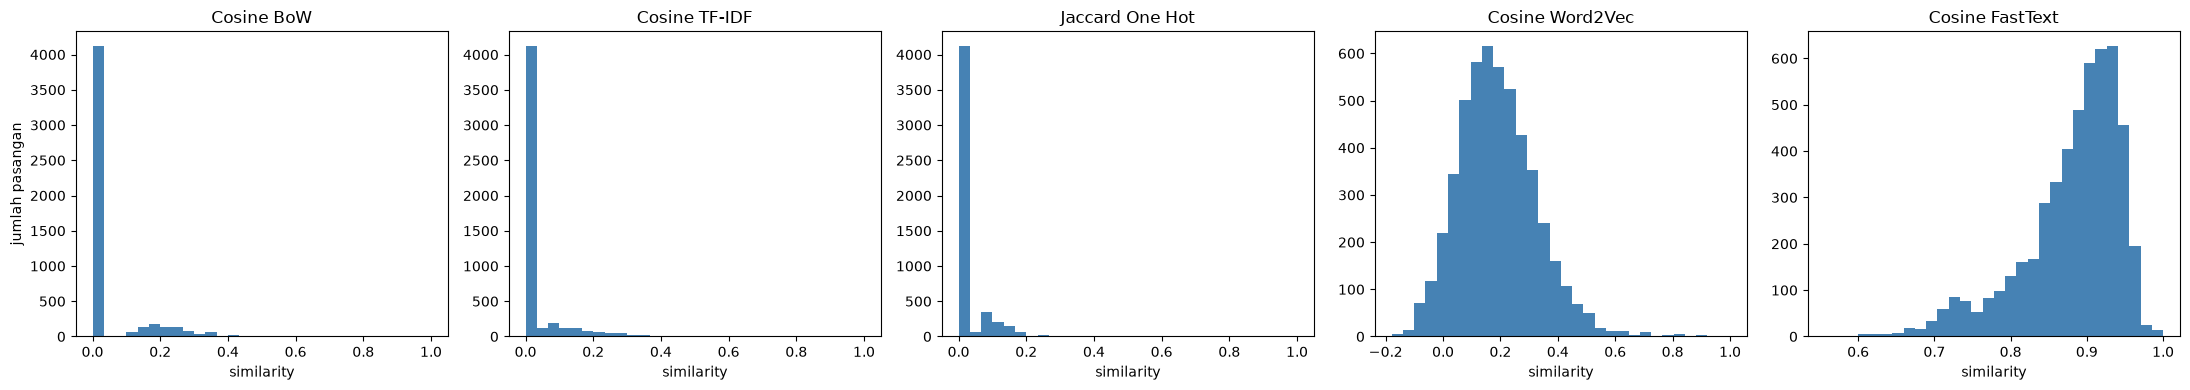

In [30]:
# Distribusi nilai similarity semua pasangan judul
fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for ax, (name, mat) in zip(axes, sim_matrices.items()):
    ax.hist(mat[rows, cols], bins=30, color="steelblue")
    ax.set_title(name)
    ax.set_xlabel("similarity")

axes[0].set_ylabel("jumlah pasangan")
plt.tight_layout()
plt.show()

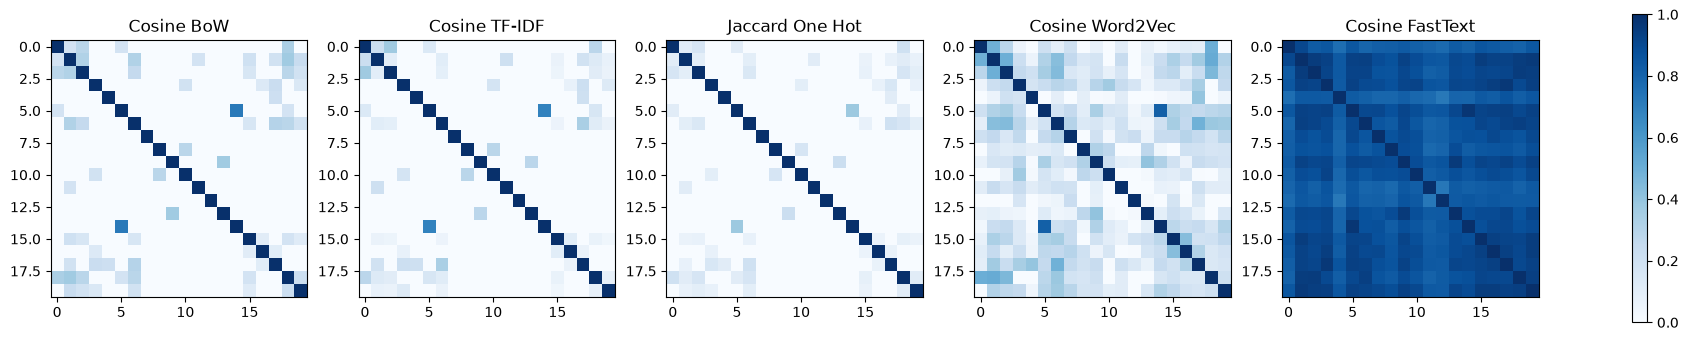

In [31]:
# Heatmap similarity 20 judul pertama
N_SHOW = 20
fig, axes = plt.subplots(1, 5, figsize=(24, 5))

for ax, (name, mat) in zip(axes, sim_matrices.items()):
    im = ax.imshow(mat[:N_SHOW, :N_SHOW], cmap="Blues", vmin=0, vmax=1)
    ax.set_title(name)

fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

In [32]:
# Korelasi Spearman: seberapa mirip urutan similarity antar metode
df_pairs = pd.DataFrame({name: mat[rows, cols] for name, mat in sim_matrices.items()})
df_pairs.corr(method="spearman").round(3)

,Cosine BoW,Cosine TF-IDF,Jaccard One Hot,Cosine Word2Vec,Cosine FastText
Cosine BoW,1.000,0.996,0.999,0.574,0.424
Cosine TF-IDF,0.996,1.000,0.997,0.573,0.420
Jaccard One Hot,0.999,0.997,1.000,0.572,0.424
Cosine Word2Vec,0.574,0.573,0.572,1.000,0.429
Cosine FastText,0.424,0.420,0.424,0.429,1.000


## Analisis Text Similarity Part 2

Hasil analisis setelah notebook dijalankan.

Berbeda dengan BoW, TF-IDF, dan One Hot, Word2Vec dan FastText tidak menghasilkan nilai similarity 0 karena setiap judul direpresentasikan sebagai rata-rata vektor kata. Word2Vec masih menghasilkan pasangan judul teratas yang masuk akal (kurs rupiah, harga emas, IHSG, pasokan BBM di Bali, tunjangan guru) dan pada query "harga emas naik" maupun "ihsg dan rupiah melemah" hasilnya relevan (judul tentang emas dan rupiah ada di posisi teratas). Korelasi Word2Vec dengan metode berbasis kata hanya sedang (sekitar 0.57), artinya Word2Vec memberi urutan kemiripan yang cukup berbeda.

FastText memberi nilai similarity yang sangat tinggi untuk hampir semua pasangan judul (rata-rata sekitar 0.88, dan 100% pasangan bernilai di atas 0.5). Hal ini terjadi karena korpus judul berita sangat kecil, sehingga potongan huruf (subword) yang dipakai bersama membuat semua vektor dokumen mirip satu sama lain dan FastText sulit membedakan judul. Hal ini terlihat pada query "ihsg dan rupiah melemah" yang justru mengambil judul yang hanya mengandung kata "dan". Kelebihan FastText terlihat pada query "penguatan perekonomian": kedua kata tidak ada di vocabulary TF-IDF maupun Word2Vec, tetapi FastText tetap bisa membuat vektornya dan mengambil judul yang mengandung kata "ekonomi" dan "perkuat".

Kesimpulannya, untuk data judul berita yang pendek dan jumlahnya sedikit, Cosine Similarity dengan TF-IDF (ditambah stopword removal) memberikan hasil yang paling stabil dan mudah dijelaskan. Jaccard cocok untuk mencari judul yang hampir duplikat. Word2Vec dan FastText berpotensi menangkap makna kata, tetapi membutuhkan korpus yang jauh lebih besar (misalnya isi berita lengkap atau lebih banyak halaman indeks) agar hasil similarity-nya lebih bermakna.